### Libraries

In [ ]:
%%capture
!pip install tqdm pandas numpy scikit-learn nltk bertopic sentence-transformers cuml accelerate

In [7]:
%load_ext autoreload
%autoreload 2

In [8]:
from tqdm import tqdm
import pandas as pd
import numpy as np

from sentence_transformers import SentenceTransformer
import torch

try:
    from cuml.manifold import UMAP
    from cuml.cluster import HDBSCAN
except ImportError:
    from umap import UMAP
    from hdbscan import HDBSCAN

In [9]:
tqdm.pandas()

In [10]:
def plot_macro_domains(df, topic_col="Macro_Domain", title=""):
    df[topic_col].value_counts(sort=True, ascending=True).plot(
        kind="barh",
        figsize=(12, 6),
        title=title,
        xlabel="Number of Paragraphs",
        ylabel="Macro Domain",
    )

In [11]:
def clustering(df, embeddings):
    df_tmp = df.copy()
    df_tmp["Sub_Issue_ID"] = -1
    global_cluster_id = 0
    sub_issue_centroids = {}

    for domain in tqdm(df_tmp["Macro_Domain"].unique(), desc="Processing Domains"):
        domain_idx = df_tmp[df_tmp["Macro_Domain"] == domain].index

        domain_emb = embeddings[domain_idx]

        umap_model = UMAP(
            n_neighbors=20, n_components=5, metric="cosine", random_state=42
        )
        reduced_emb = umap_model.fit_transform(domain_emb)

        hdbscan_model = HDBSCAN(
            min_cluster_size=50, min_samples=10, cluster_selection_method="leaf"
        )
        local_labels = hdbscan_model.fit_predict(reduced_emb)

        # Map to Global IDs
        unique_labels = np.unique(local_labels)
        for local_label in unique_labels:
            if local_label == -1:
                continue

            cluster_mask = local_labels == local_label
            cluster_idx = domain_idx[cluster_mask]

            df_tmp.loc[cluster_idx, "Sub_Issue_ID"] = global_cluster_id

            # Save centroid
            sub_issue_centroids[global_cluster_id] = domain_emb[cluster_mask].mean(
                axis=0
            )
            global_cluster_id += 1

    return df_tmp, sub_issue_centroids

In [12]:
def extract_repr_docs(df, sub_issue_centroids, topk):
    sub_issue_rep_docs = {}

    df_tmp = df.copy()

    for cid, centroid in tqdm(
        sub_issue_centroids.items(), desc="Extracting Representative Docs"
    ):
        c_idx = df_tmp[df_tmp["Sub_Issue_ID"] == cid].index
        c_emb = embeddings[c_idx]

        # Calculate distance to centroid
        dists = np.linalg.norm(c_emb - centroid, axis=1)

        # Get top K closest documents
        top_K_local_idx = np.argsort(dists)[:topk]
        top_K_global_idx = c_idx[top_K_local_idx]

        sub_issue_rep_docs[cid] = df_tmp.loc[top_K_global_idx, "TEXT_SPAN"].tolist()

    return sub_issue_rep_docs

In [105]:
import requests
import json


def extract_topic_label(
    system_prompt: str,
    domain: str,
    docs: str,
    temperature: float = 0.2,
    top_p: float = 0.8,
    max_tokens: int = 64,
    endpoint: str = "https://vllm-gateway-runai-sharedllm-ralf.inference.compute.datascience.ch/v1/chat/completions",
):
    chat_prompt = f"Domain:\n{domain}\n\nParliamentary excerpts:\n{docs}"

    payload = {
        "model": "Qwen/Qwen3.5-35B-A3B-GPTQ-Int4",
        "messages": [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": chat_prompt},
        ],
        "temperature": temperature,
        "top_p": top_p,
        "max_tokens": max_tokens,
        "chat_template_kwargs": {"enable_thinking": False},
    }

    r = requests.post(
        endpoint,
        headers={
            "Content-Type": "application/json",
            "Authorization": f"Bearer {API_KEY}",
        },
        json=payload,
        timeout=60,
    )

    if not r.ok:
        raise RuntimeError(f"API error {r.status_code}: {r.text}")

    content = r.json()["choices"][0]["message"]["content"].strip()
    label = content.replace("label:", "").strip()
    return label

In [92]:
def refine_topic(
    df,
    rep_docs,
    labels,
    system_prompt,
    save_path="sub_issue_labels_cache.json",
    save_every=10,
    **qwen_params,
):

    try:
        with open(save_path, "r") as f:
            labels.update(json.load(f))
    except FileNotFoundError:
        pass

    items = sorted(rep_docs.items(), key=lambda x: x[0])

    for i, (cid, docs) in enumerate(tqdm(items, desc="LLM Naming")):
        if cid in labels:
            continue

        subset = df[df["Sub_Issue_ID"] == cid]["Macro_Domain"]
        if subset.empty:
            parent_domain = "Unknown"
        else:
            parent_domain = subset.iloc[0]

        formatted_docs = "\n".join(f"- {d}" for d in docs[:10])

        label = extract_topic_label(
            system_prompt=system_prompt,
            domain=parent_domain,
            docs=formatted_docs,
            **qwen_params,
        )

        labels[cid] = label

        if (i + 1) % save_every == 0:
            with open(save_path, "w") as f:
                json.dump(labels, f, ensure_ascii=False, indent=2)

    with open(save_path, "w") as f:
        json.dump(labels, f, ensure_ascii=False, indent=2)

    return labels

# Speech Data

Load the speech data

In [15]:
df = pd.read_parquet("clean_paragraphs.parquet")
df

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name
0,81893,81893_p0,La commission propose de ne pas donner suite à...,President,FR,Bugnon André
1,81894,81894_p0,"Ich möchte Sie nur nochmals bitten, das Result...",For the committee,DE,Widmer Hans
2,81894,81894_p1,"In diesem Sinne bitte ich Sie nochmals, den An...",For the committee,DE,Widmer Hans
3,81895,81895_p0,Der Bundesrat beantragt die Annahme des Postul...,Member of the federal council,DE,Schmid Samuel
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel
...,...,...,...,...,...,...
303379,288681,288681_p11,"En commission, une minorité avait, quant à ell...",For the committee,FR,Python Valentine
303380,288681,288681_p12,La proposition individuelle Bäumle déposée hie...,For the committee,FR,Python Valentine
303381,288681,288681_p13,En ce qui concerne le cas précis de cette prop...,For the committee,FR,Python Valentine
303382,288681,288681_p14,La majorité de la commission désire prendre en...,For the committee,FR,Python Valentine


# Bills (SwissDomainBERT2)

Load the 21 topics (from Bills)

In [16]:
topic_df = pd.read_parquet("240102_bills_swissdomainbert2_predictions.parquet")
bills_topics = topic_df["domain_name_prediction_swissdomainbert2"].unique().tolist()
print(f"Found {len(bills_topics)} unique topics: {bills_topics}")
topic_df.head(10)

Found 21 unique topics: ['Civil Rights', 'Technology, Communication', 'International Affairs', 'Government Operations', 'Economy', 'Education, Research', 'Culture, Arts, Religion, Sport, Entertainment', 'Public Finances, Taxation', 'Agriculture', 'Social Welfare', 'Labor', 'Health', 'National Security, Armed Forces, Defense', 'Environment', 'Energy', '(Public) Transportation', 'Finances, Financial Sector', 'Spatial Planing, Civil Engineering', 'Migration', 'Parliamentary Procedure', 'Criminal Law']


,bill_number,text,date,chamber,domain_id,source,language,time_span_decade,time_span_25y,domain_id_prediction_swissdomainbert2,domain_logits_swissdomainbert2,domain_name_prediction_swissdomainbert2,embeddings_swissdomainbert2,umap_swissdomainbert2
0,...,"Motion der Kommissionsminderheit (Renschier, ....",1987-01-01,Unknown,NaN,graph,DE,1980.0,1975.0,3,"[1.4315958196675638e-07, 8.955157682066783e-05...",Civil Rights,"[-0.6744987368583679, -0.5489828586578369, -0....","[3.0162856578826904, 6.312497615814209]"
1,0.10335,"195. Freymond, vom 26. Juni 1969.Ein ausländis...",1969-06-26,Nationalrat,NaN,graph,DE,1960.0,1950.0,14,"[3.644416892711888e-06, 3.176500104018487e-05,...","Technology, Communication","[0.3503628969192505, -0.17170414328575134, -0....","[6.8938212394714355, 5.891744136810303]"
2,00.001,Der Europarat beging 1999 sein 50-jähriges Bes...,2000-01-12,Ständerat,NaN,graph,DE,2000.0,2000.0,13,"[2.939555633929558e-05, 4.6187258703866974e-05...",International Affairs,"[0.4193879961967468, -0.16224949061870575, 0.2...","[13.971299171447754, -0.31970149278640747]"
3,00.003,In seinem Postulat vom 6. Oktober 1976 beauftr...,2000-01-19,Ständerat,13.0,graph,DE,2000.0,2000.0,13,"[2.9378930776147172e-05, 3.518968151183799e-05...",International Affairs,"[0.42163193225860596, -0.15665242075920105, 0....","[13.986701011657715, -0.2620127201080322]"
4,00.006,Bericht des Bundesrates über seine Geschäftsfü...,2000-03-09,Nationalrat,NaN,graph,DE,2000.0,2000.0,15,"[7.351007297984324e-06, 5.184900146559812e-06,...",Government Operations,"[-0.26835861802101135, -0.4732978343963623, 0....","[-1.9103219509124756, -2.2852351665496826]"
5,00.007,Das Einleitungskapiteldes Berichts ist der Bed...,2000-01-12,Nationalrat,20.0,graph,DE,2000.0,2000.0,20,"[2.210132333857473e-05, 1.302836972172372e-05,...",Economy,"[-0.5453465580940247, -0.3741756081581116, 0.1...","[3.557896614074707, 2.900557279586792]"
6,00.008,Das Bundesgesetz vom 7. Oktober 1983 über den ...,2000-03-01,Ständerat,NaN,graph,DE,2000.0,2000.0,6,"[0.29752904176712036, 0.0001268720516236499, 0...","Education, Research","[-1.0216357707977295, 0.07308592647314072, -0....","[6.255590915679932, 3.2767133712768555]"
7,00.009,Mit dem Bundesbeschluss vom 17. Dezember 1998 ...,2000-01-26,Nationalrat,16.0,graph,DE,2000.0,2000.0,16,"[4.379471647553146e-05, 0.00014013775216881186...","Culture, Arts, Religion, Sport, Entertainment","[-1.3953583240509033, -0.15909360349178314, 0....","[-2.8011155128479004, 1.0940746068954468]"
8,00.010,Die Staatsrechnung 1999 präsentiert sich erneu...,2000-03-29,Nationalrat,19.0,graph,DE,2000.0,2000.0,19,"[0.00013363057223614305, 1.5576872101519257e-0...","Public Finances, Taxation","[-1.3426238298416138, -0.4670485258102417, 0.1...","[6.670615196228027, 10.868708610534668]"
9,00.011,Mit dem ersten Nachtrag zum Voranschlag 2000 e...,2000-03-29,Nationalrat,16.0,graph,DE,2000.0,2000.0,16,"[0.00501673761755228, 0.00025986498803831637, ...","Culture, Arts, Religion, Sport, Entertainment","[-1.2834326028823853, -0.5486190319061279, 0.0...","[-4.552356243133545, -6.336331367492676]"


# Embeddings (Qwen3-0.6B)

Instantiate the Embedding model

In [17]:
# Load the embedding model
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-0.6B"
embedder = SentenceTransformer(
    EMBEDDING_MODEL,
    trust_remote_code=True,
    model_kwargs={
        "torch_dtype": torch.bfloat16,
        "attn_implementation": "sdpa",
    },
    processor_kwargs={"padding_side": "left"},
)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

In [18]:
# Load pre-computed embeddings
embeddings = np.load(f"paragraph_embeddings_{EMBEDDING_MODEL.split('/')[-1]}.npy")

# Normalize embeddings to unit length
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
embeddings.shape

(303384, 1024)

### Embed the 21 topics

In [19]:
domain_embeddings = embedder.encode(bills_topics, normalize_embeddings=True)
domain_embeddings.shape

(21, 1024)

### Similarity Matrix

We compute the cosine similarity between the topic embeddings and the paragraph embeddings.

In [20]:
sim_matrix = embeddings @ domain_embeddings.T
sim_matrix.shape

(303384, 21)

We then assign to each paragraph the topic with the highest similarity, no matter what the similarity value is.

We expect them to be quite low since the topic are general and the paragraphs are very specific.

In [21]:
best_domain_idx = np.argmax(sim_matrix, axis=1)
best_domain_scores = np.max(sim_matrix, axis=1)

In [22]:
df_with_topics = df.copy()

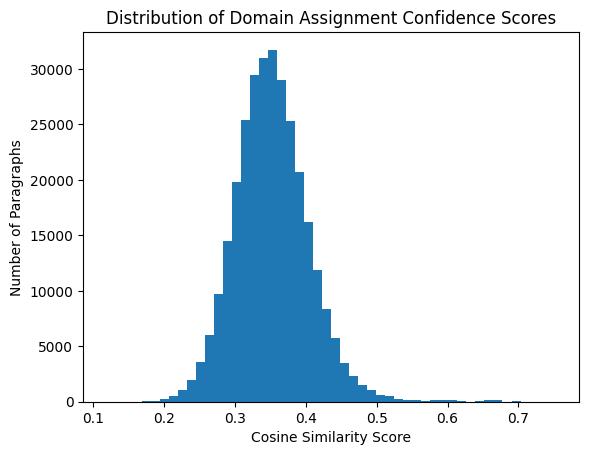

In [23]:
import matplotlib.pyplot as plt

plt.hist(best_domain_scores, bins=50)
plt.title("Distribution of Domain Assignment Confidence Scores")
plt.xlabel("Cosine Similarity Score")
plt.ylabel("Number of Paragraphs")
plt.show()

### (Optional) CrossEncoder (Bi-Encoder) with TopK

Instead of picking the topic with the highest similarity, we can use a CrossEncoder to re-rank the top K most similar topics for each paragraph.

In [24]:
# from sentence_transformers import CrossEncoder

# reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")


# def rerank_domain(row, top_k_indices):
#     paragraph = row["TEXT_SPAN"]
#     # Get the names of the Top-K domains by Cosine Similarity
#     candidates = [bills_topics[idx] for idx in top_k_indices]

#     # Format as pairs for the Cross-Encoder
#     pairs = [(paragraph, cand) for cand in candidates]

#     # Predict scores
#     scores = reranker.predict(pairs)

#     # Return the domain with the highest cross-attention score
#     return candidates[np.argmax(scores)]


# # Top-3 candidate domains for each paragraph based on cosine similarity
# top_k_indices = np.argsort(sim_matrix, axis=1)[:, -3:]

# tqdm.pandas()
# df_with_topics["Macro_Domain"] = df_with_topics.progress_apply(
#     lambda row: rerank_domain(row, top_k_indices[row.name]), axis=1
# )

We assign the macro domain topic along with the similarity score to each paragraph.

In [25]:
df_with_topics["Macro_Domain"] = [bills_topics[i] for i in best_domain_idx]
df_with_topics["Domain_Confidence"] = best_domain_scores
df_with_topics

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Macro_Domain,Domain_Confidence
0,81893,81893_p0,La commission propose de ne pas donner suite à...,President,FR,Bugnon André,Parliamentary Procedure,0.317283
1,81894,81894_p0,"Ich möchte Sie nur nochmals bitten, das Result...",For the committee,DE,Widmer Hans,Parliamentary Procedure,0.360386
2,81894,81894_p1,"In diesem Sinne bitte ich Sie nochmals, den An...",For the committee,DE,Widmer Hans,Parliamentary Procedure,0.277510
3,81895,81895_p0,Der Bundesrat beantragt die Annahme des Postul...,Member of the federal council,DE,Schmid Samuel,Parliamentary Procedure,0.367392
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,"National Security, Armed Forces, Defense",0.323814
...,...,...,...,...,...,...,...,...
303379,288681,288681_p11,"En commission, une minorité avait, quant à ell...",For the committee,FR,Python Valentine,Parliamentary Procedure,0.332337
303380,288681,288681_p12,La proposition individuelle Bäumle déposée hie...,For the committee,FR,Python Valentine,Agriculture,0.314368
303381,288681,288681_p13,En ce qui concerne le cas précis de cette prop...,For the committee,FR,Python Valentine,Parliamentary Procedure,0.343919
303382,288681,288681_p14,La majorité de la commission désire prendre en...,For the committee,FR,Python Valentine,"Education, Research",0.311028


Fully inflated by the parliamentary procedure which we will discard (or analyze separately).

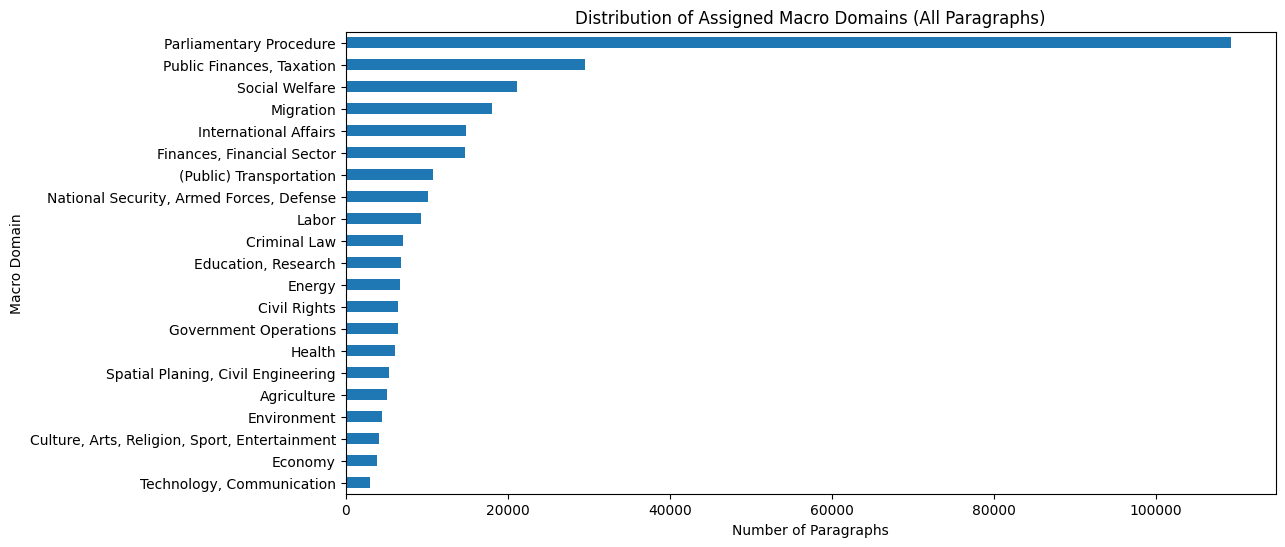

In [26]:
plot_macro_domains(
    df_with_topics,
    topic_col="Macro_Domain",
    title="Distribution of Assigned Macro Domains (All Paragraphs)",
)

True distribution without the parliamentary procedure looks more balanced.

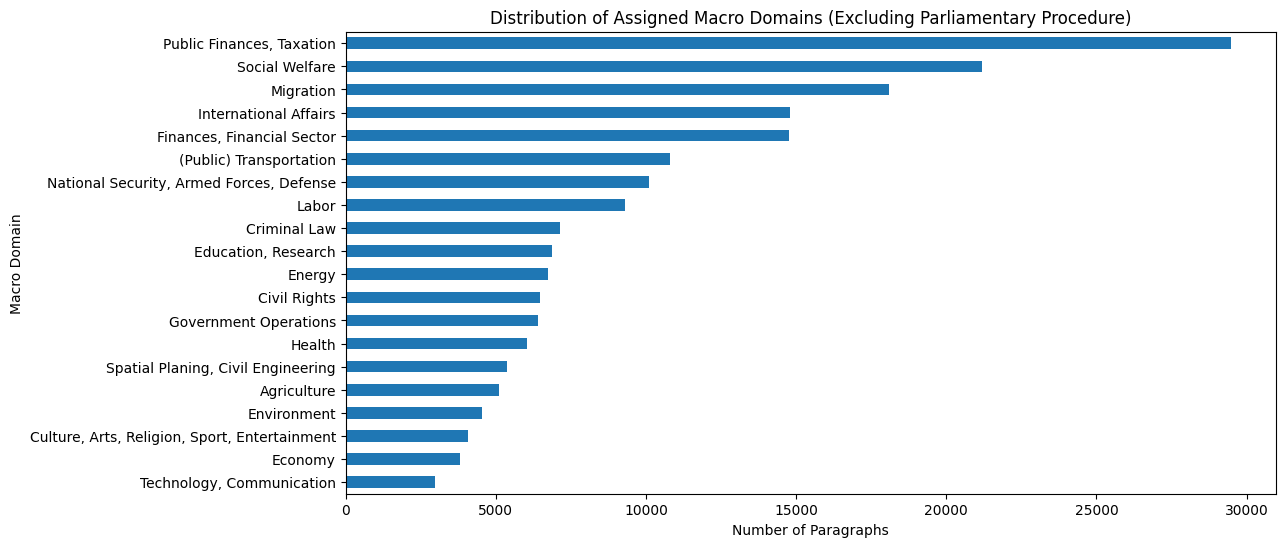

In [27]:
df_topics_clean = df_with_topics[
    df_with_topics["Macro_Domain"] != "Parliamentary Procedure"
]
plot_macro_domains(
    df_topics_clean,
    topic_col="Macro_Domain",
    title="Distribution of Assigned Macro Domains (Excluding Parliamentary Procedure)",
)

### Clustering

After removing the parliamentary procedure, we can cluster the paragraphs based on their topic assignments and similarity scores to identify subtopics or themes within each macro domain.

We run local UMAP to project the high-dimensional topic embeddings and then apply HDBSCAN to identify clusters of paragraphs that are closely related in terms of their topic assignments and similarity scores. We start from leaf nodes and then we can aggregate them to the parent nodes to see how the clusters evolve across the hierarchy of topics.

In [28]:
df_topics_clean, sub_issue_centroids = clustering(df_topics_clean, embeddings)

Processing Domains:   0%|          | 0/20 [00:00<?, ?it/s]/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
Processing Domains:   5%|▌         | 1/20 [00:19<06:15, 19.75s/it]/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
Processing Domains:  10%|█         | 2/20 [00:43<06:41, 22.32s/it]/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
Processing Domains:  15%|█▌        | 3/20 [01:07<06:26, 22.73s/it]/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs va

In [29]:
print("Original data:", df.shape[0])
print("Without macro Parliamentary Procedure:", df_topics_clean.shape[0])
print(
    "Noisy (Sub_Issue_ID = -1):",
    (df_topics_clean["Sub_Issue_ID"] == -1).sum(),
    f"({(df_topics_clean['Sub_Issue_ID'] == -1).mean():.2%})",
)
print(
    "Unique Sub-Issue IDs (excluding noise):",
    df_topics_clean["Sub_Issue_ID"].nunique() - 1,
)

Original data: 303384
Without macro Parliamentary Procedure: 194098
Noisy (Sub_Issue_ID = -1): 106507 (54.87%)
Unique Sub-Issue IDs (excluding noise): 762


<Axes: title={'center': 'Distribution of Sub-Issue Sizes (Excluding Noise)'}, xlabel='Number of Paragraphs', ylabel='Sub-Issue ID'>

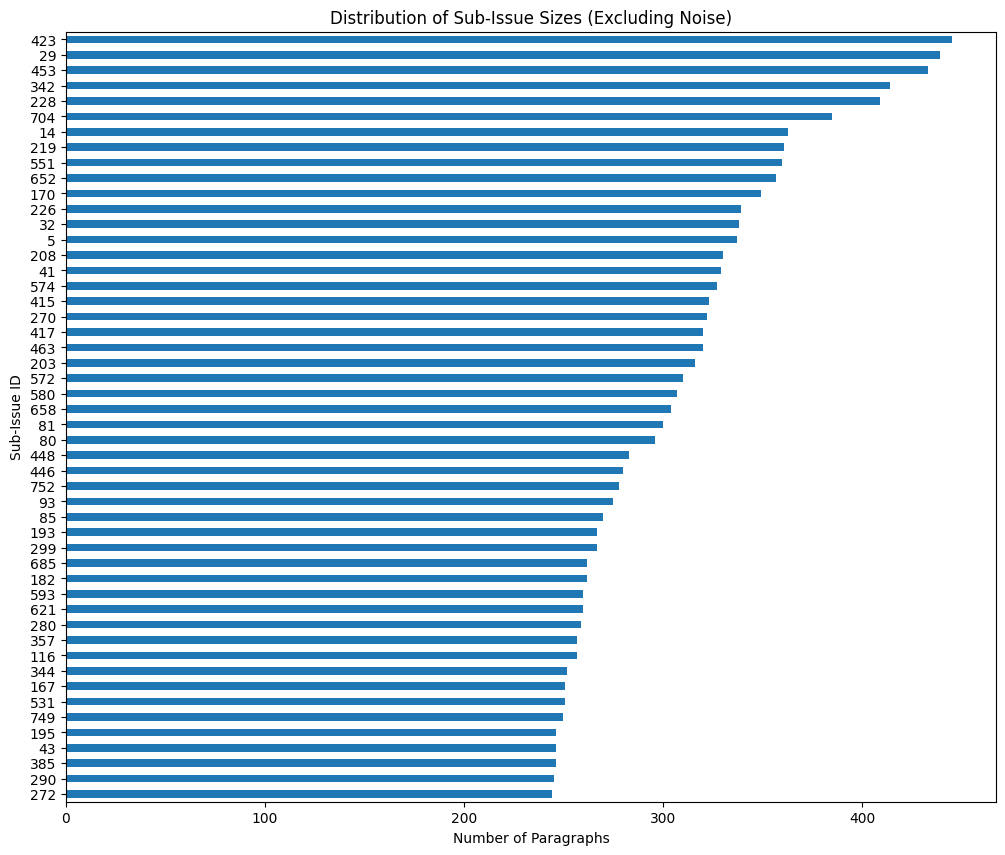

In [30]:
df_topics_clean[df_topics_clean["Sub_Issue_ID"] != -1]["Sub_Issue_ID"].value_counts(
    sort=True, ascending=True
).tail(50).plot(
    kind="barh",
    figsize=(12, 10),
    title="Distribution of Sub-Issue Sizes (Excluding Noise)",
    xlabel="Number of Paragraphs",
    ylabel="Sub-Issue ID",
)

In [123]:
import pandas as pd
import numpy as np
import plotly.express as px
from umap import UMAP

sub_issue_ids = list(sub_issue_centroids.keys())
centroid_matrix = np.array([sub_issue_centroids[cid] for cid in sub_issue_ids])

reducer_3d = UMAP(n_neighbors=15, n_components=3, metric="cosine", random_state=42)
centroid_3d = reducer_3d.fit_transform(centroid_matrix)

plot_df = pd.DataFrame(
    {
        "x": centroid_3d[:, 0],
        "y": centroid_3d[:, 1],
        "z": centroid_3d[:, 2],
        "Sub_Issue_ID": sub_issue_ids,
    }
)

domain_map = (
    df_topics_clean[df_topics_clean["Sub_Issue_ID"] != -1]
    .groupby("Sub_Issue_ID")["Macro_Domain"]
    .first()
    .to_dict()
)
plot_df["Domain"] = plot_df["Sub_Issue_ID"].map(domain_map).fillna("Uncategorized")

fig = px.scatter_3d(
    plot_df,
    x="x",
    y="y",
    z="z",
    color="Domain",
    hover_name="Sub_Issue_ID",
    opacity=0.9,
    size_max=10,
    color_discrete_sequence=px.colors.qualitative.Dark24,
)

fig.update_layout(margin=dict(l=0, r=0, b=0, t=20))
fig.show()

/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


To extract the representative paragraphs for each cluster, we can compute the centroid of the cluster in the embedding space and then find the paragraphs that are closest to the centroid. These representative paragraphs can provide insights into the main themes or subtopics within each macro domain, and can be used for labeling the cluster using an LLM.

In [32]:
sub_issue_rep_docs = extract_repr_docs(df_topics_clean, sub_issue_centroids, topk=5)

Extracting Representative Docs: 100%|██████████| 762/762 [00:01<00:00, 676.50it/s]


### LLM cluster labeling

In [65]:
with open("/home/matteo/.config/io.datasette.llm/keys.json", "r") as f:
    keys = json.load(f)

API_KEY = keys["sdsc-key"]

We prompt Qwen3.5-35B-A3B-GPTQ-Int4 to label the clusters based on the representative paragraphs.

From docs (https://huggingface.co/Qwen/Qwen3.5-35B-A3B-GPTQ-Int4):

We recommend using the following set of sampling parameters for generation

- Thinking mode for general tasks: temperature=1.0, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0
- Thinking mode for precise coding tasks (e.g. WebDev): temperature=0.6, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=0.0, repetition_penalty=1.0
- Instruct (or non-thinking) mode for general tasks: temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0
- Instruct (or non-thinking) mode for reasoning tasks: temperature=1.0, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0

Please note that the support for sampling parameters varies according to inference frameworks.

I will go with: Instruct (or non-thinking) mode for general tasks: temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0


In [106]:
qwen_params = {
    "temperature": 0.2,  # Adjusted for more deterministic output
    "top_p": 0.8,
}

In [107]:
SYSTEM_PROMPT = """
Answer ONLY in English.

You are a Swiss parliamentary policy analyst and political data scientist.

Your task is to assign ONE precise policy sub-issue label to a cluster of parliamentary speech excerpts from the Swiss Federal Parliament.

The texts may contain:
- German, French, or Italian
- Swiss institutional terminology
- references to cantonal/federal competencies
- referendum-related legislation
- administrative law
- parliamentary procedural language

Treat multilingual terminology as referring to the same policy issue when appropriate.
Always translate the final label into English.

Your goal is to identify the MOST SPECIFIC recurring legislative or regulatory issue discussed.

A valid label should describe:
- a concrete policy mechanism
- a legislative reform
- a regulatory instrument
- a funding mechanism
- an administrative procedure
- a tax/subsidy structure
- a treaty implementation issue
- a sector-specific policy measure

Prefer legislatively actionable issues over broad political themes.

The label MUST:
- be concise
- contain 2-6 words
- use a noun phrase
- use singular form when possible
- be understandable without context
- avoid verbs and full sentences
- avoid ideological framing
- avoid party names unless central
- avoid procedural parliamentary language

DO NOT output broad domains such as:
- Health
- Economy
- Migration
- Energy
- Environment
- Agriculture
- Security
- Social policy
- Climate policy

DO NOT summarize at the thematic or ideological level.

Prefer:
- Hospital DRG reimbursement
- Agricultural diesel tax exemptions
- Pension conversion rate reform
- Rail freight infrastructure financing
- Nuclear phase-out timeline
- CO2 levy redistribution
- Cross-border commuter taxation
- Asylum detention procedures
- TARMED tariff revision
- Cantonal hospital planning
- Building emissions standards
- Fiscal equalization reform
- Schengen/Dublin implementation

Avoid:
- Healthcare reform
- Climate change
- Energy debate
- Migration issues
- Economic policy
- Social inequality
- Environmental protection

If multiple issues appear, identify the dominant recurring legislative topic.

If the excerpts are too broad, incoherent, procedural, or contain no stable policy issue, output exactly:
Mixed parliamentary topics

Output format:
label: <sub-issue label>
"""

In [108]:
CHAT_PROMPT = """
Domain:
{domain}

Context:
The following excerpts were grouped automatically using multilingual clustering of Swiss parliamentary speeches.
The cluster may contain noisy or partially unrelated excerpts.
Focus on the dominant recurring legislative or regulatory issue.

Parliamentary excerpts:
{docs}

Identify the single most specific recurring Swiss policy sub-issue.
"""

In [109]:
df_topics = df_topics_clean[df_topics_clean["Sub_Issue_ID"] != -1].copy()

In [110]:
sub_issue_labels = {}
sub_issue_labels = refine_topic(
    df_topics,
    sub_issue_rep_docs,
    sub_issue_labels,
    system_prompt=SYSTEM_PROMPT,
    **qwen_params,
)

LLM Naming:   2%|▏         | 12/762 [00:07<08:10,  1.53it/s]


KeyboardInterrupt: 

In [111]:
sub_issue_labels

{'0': '"Domestic agricultural supply security"',
 '1': '"Grenzwachtkorps personnel staffing"',
 '2': '"War material export regulation"',
 '3': '"Sub-munition weapons convention ratification"',
 '4': '"Label": "Military firearm retention reform"',
 '5': '"Rüstungsexportkontrollverordnung"',
 '6': '"Cyberdefence strategy implementation"',
 '7': '"Airspace security and drone regulation"',
 '8': '"Subsidiary army engagement for civil protection"',
 '9': '"Cyberdefense strategy and governance"',
 0: 'Domestic agricultural supply security',
 1: 'Border guard personnel staffing',
 2: 'War material export regulation',
 3: 'Sub-munitions convention ratification',
 4: 'Military firearm retention rules',
 5: 'Rüstungsexportkontrollverordnung',
 6: 'Cyberdefence strategy implementation',
 7: 'Swiss airspace security funding',
 8: 'Military support for foreign representation protection',
 9: 'Federal cyber defense strategy reform',
 10: 'Civil service admission restrictions',
 11: 'Counter-terroris

In [ ]:
df_topics["Sub_Issue_Name"] = df_topics["Sub_Issue_ID"].map(sub_issue_labels)

In [117]:
df_topics[df_topics["Sub_Issue_Name"] != "Noise"]

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Macro_Domain,Domain_Confidence,Sub_Issue_ID,Sub_Issue_Name
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,"National Security, Armed Forces, Defense",0.323814,29,NaN
6,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel,"National Security, Armed Forces, Defense",0.370678,28,NaN
9,83146,83146_p0,Erlauben Sie mir noch ein paar Bemerkungen.,For the committee,DE,Schwaller Urs,"Culture, Arts, Religion, Sport, Entertainment",0.279201,41,NaN
12,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,"Public Finances, Taxation",0.301651,113,NaN
16,83147,83147_p1,"La majorité de la commission, à notre avis ave...",President of the federal council,FR,Couchepin Pascal,Social Welfare,0.350145,221,NaN
...,...,...,...,...,...,...,...,...,...,...
303362,288680,288680_p7,"Fünftens sieht der Bundesrat vor, die Ausbildu...",Member of the federal council,DE,Amherd Viola,"National Security, Armed Forces, Defense",0.300353,32,NaN
303369,288681,288681_p1,"La commission, durant ses travaux, a également...",For the committee,FR,Python Valentine,Environment,0.342500,478,NaN
303373,288681,288681_p5,Une minorité de la commission soutient que ces...,For the committee,FR,Python Valentine,"Technology, Communication",0.341204,756,NaN
303375,288681,288681_p7,"De plus, il est désormais clairement établi, é...",For the committee,FR,Python Valentine,"Technology, Communication",0.310194,756,NaN


<Axes: title={'center': 'Distribution of Named Sub-Issues'}, xlabel='Number of Paragraphs', ylabel='Sub-Issue Name'>

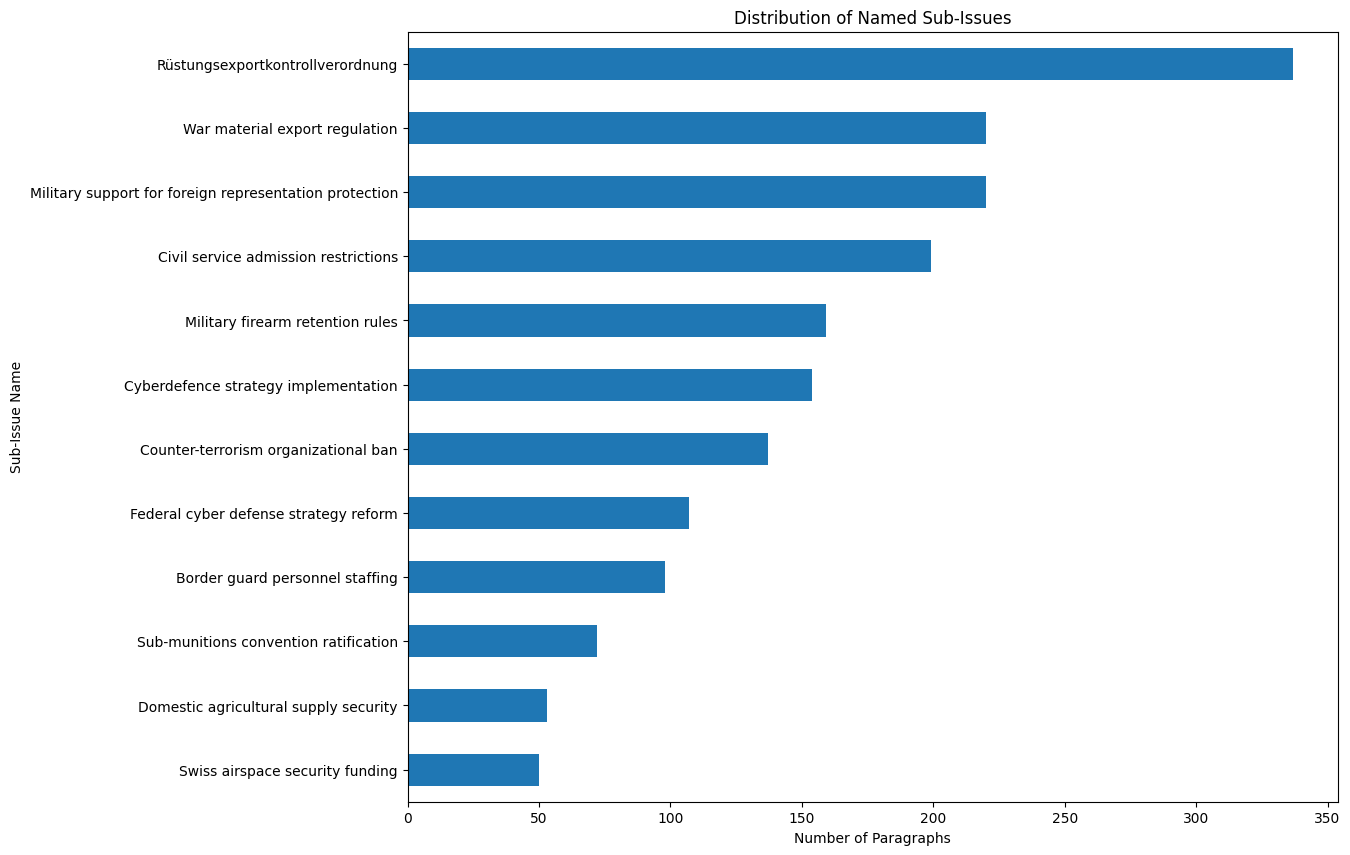

In [118]:
df_topics[df_topics["Sub_Issue_Name"] != "Noise"]["Sub_Issue_Name"].value_counts(
    sort=True, ascending=True
).tail(50).plot(
    kind="barh",
    figsize=(12, 10),
    title="Distribution of Named Sub-Issues",
    xlabel="Number of Paragraphs",
    ylabel="Sub-Issue Name",
)

In [122]:
df_topics

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Macro_Domain,Domain_Confidence,Sub_Issue_ID,Sub_Issue_Name
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,"National Security, Armed Forces, Defense",0.323814,29,NaN
6,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel,"National Security, Armed Forces, Defense",0.370678,28,NaN
9,83146,83146_p0,Erlauben Sie mir noch ein paar Bemerkungen.,For the committee,DE,Schwaller Urs,"Culture, Arts, Religion, Sport, Entertainment",0.279201,41,NaN
12,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,"Public Finances, Taxation",0.301651,113,NaN
16,83147,83147_p1,"La majorité de la commission, à notre avis ave...",President of the federal council,FR,Couchepin Pascal,Social Welfare,0.350145,221,NaN
...,...,...,...,...,...,...,...,...,...,...
303362,288680,288680_p7,"Fünftens sieht der Bundesrat vor, die Ausbildu...",Member of the federal council,DE,Amherd Viola,"National Security, Armed Forces, Defense",0.300353,32,NaN
303369,288681,288681_p1,"La commission, durant ses travaux, a également...",For the committee,FR,Python Valentine,Environment,0.342500,478,NaN
303373,288681,288681_p5,Une minorité de la commission soutient que ces...,For the committee,FR,Python Valentine,"Technology, Communication",0.341204,756,NaN
303375,288681,288681_p7,"De plus, il est désormais clairement établi, é...",For the committee,FR,Python Valentine,"Technology, Communication",0.310194,756,NaN


In [121]:
df_topics.dropna().to_csv("df_topics_with_labels.csv", index=False)